### Downloading GHS-POP multitemporal gridded population data via STAC

This notebook downloads from a cloud-native mirror of the European Commission Joint Research Centre's GHS-POP R2023A population grids, provided in twelve five-yearly epochs from 1975 to 2030 at 100m in World Mollweidge (ESRI:54009).

The original global rasters are stored in deflated ZIPs without internal overviews, preventing partial reads and requiring the download of the whole file. The mirror converts them into Cloud Optimized GeoTiffs with overviews and embedded statistics, allowing partial reads over HTTP.

This is important for the project's AOI, which only covers the urban area of General Santos.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
import xarray as xr

import rioxarray as rxr
from rioxarray.merge import merge_arrays
from rioxarray.exceptions import NoDataInBounds

from shapely.geometry import box, shape
from shapely import Polygon, transform
from pyproj import Transformer


import stackstac as stk
import pystac_client
import duckdb

from pathlib import Path

In [2]:
DATA_DIR = Path().resolve().parent / 'data'

fp_urban_area = list(DATA_DIR.rglob('*vector*/*.shp'))[1]
fp_urban_stat = list(DATA_DIR.rglob('*statistics*/*.xlsx'))[0]

Step 1. Query AOI from GHS WUP multi-temporal urban area polygon dataset

In [3]:
BASE = 'https://data.source.coop/nlebovits/ghsl'
OLD_CRS = 'ESRI:54009'  # World Mollweide (Original CRS by EU JRC GHS)
# CRS = 'EPSG:6933'       # NSIDC EASE-GRid 2.0 (Lambert cylindrical equal area)
CRS = 'EPSG:32651'      # UTM Zone 51N (Philippines)  
X0, Y0, SPAN = -18_041_000, 9_000_000, 1_000_000

In [4]:
start_year, end_year = 1975, 2025
years = [y for y in range(1975, 2031, 5) if start_year <= y <= end_year]

In [5]:
con = duckdb.connect()
con.execute('INSTALL spatial; LOAD spatial;')

In [6]:
un_loc_name = 'Philippines'
uc_name = 'General Santos'

query_aoi = f"""
SELECT ua.*, us.UCname, us.AREA_km2, us.POP, us.BU_km2
FROM '{str(fp_urban_area)}' AS ua
JOIN read_xlsx(
    '{str(fp_urban_stat)}',
    sheet = 'UC_STATS'
) AS us ON ua.ID_MTUC = us.ID_MTUC
WHERE
    us.UNLocName = '{un_loc_name}'
    AND us.UCname = '{uc_name}'
    AND ua.Year BETWEEN 1975 AND 2025
"""

gdf_aoi = gpd.GeoDataFrame.from_arrow(
    con.sql(query_aoi).arrow(),
).set_crs(OLD_CRS)

gdf_aoi

,ID_MTUC,Year,ID_UC_G0,geom,UCname,AREA_km2,POP,BU_km2
0,5764_1975,1975,5764,"POLYGON ((12501000 758000, 12503000 758000, 12...",General Santos,27.0,70734.01301,5.696239
1,5764_1980,1980,5764,"POLYGON ((12501000 758000, 12504000 758000, 12...",General Santos,49.0,155069.82750,9.512221
2,5764_1985,1985,5764,"POLYGON ((12502000 758000, 12504000 758000, 12...",General Santos,57.0,200918.16740,10.734503
3,5764_1990,1990,5764,"POLYGON ((12501000 759000, 12502000 759000, 12...",General Santos,61.0,251855.30020,11.805930
4,5764_1995,1995,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,85.0,345059.56330,14.459404
5,5764_2000,2000,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,93.0,420483.76060,15.121916
6,5764_2005,2005,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,99.0,449031.74650,15.647108
7,5764_2010,2010,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,103.0,470842.90160,16.086328
8,5764_2015,2015,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,103.0,472349.55550,16.439053
9,5764_2020,2020,5764,"POLYGON ((12499000 762000, 12500000 762000, 12...",General Santos,103.0,473667.80570,16.768007


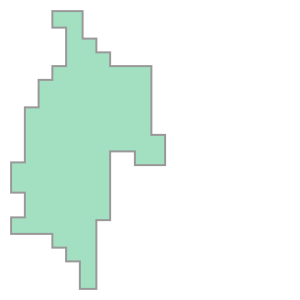

In [7]:
# Get geometry of largest urban area polygon in time series
geom_aoi = gdf_aoi.sort_values(
    by='AREA_km2', 
    ascending=False
).head(1).reset_index().buffer(100, cap_style='square', join_style='mitre').geometry.values[0]

geom_aoi

In [8]:
gdf_aoi.crs

<Projected CRS: ESRI:54009>
Name: World_Mollweide
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Coordinate Operation:
- name: World_Mollweide
- method: Mollweide
Datum: World Geodetic System 1984
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [9]:
geom_aoi.bounds

(12493900.0, 743900.0, 12505100.0, 764100.0)

Following cells were developed with LLM assistance (Claude)

In [10]:
# 1. All tiles touched by the AOI bbox (not just one corner)
minx, miny, maxx, maxy = geom_aoi.bounds
col0, col1 = int((minx - X0) // SPAN) + 1, int((maxx - X0) // SPAN) + 1
row0, row1 = int((Y0 - maxy) // SPAN) + 1, int((Y0 - miny) // SPAN) + 1
tiles = [f'R{r}_C{c}' for r in range(row0, row1 + 1) for c in range(col0, col1 + 1)]
tiles

['R9_C31']

In [11]:
# 2. One parquet read per epoch instead of thousands of JSON requests
#    (also tells you which tiles actually exist; ocean-only tiles are omitted)
def existing_tiles(year):
    ids = ', '.join(f"'pop-{year}-{t}'" for t in tiles)
    rows = con.execute(
        f"SELECT id FROM read_parquet('{BASE}/pop-{year}/items.parquet') WHERE id IN ({ids})"
    ).fetchall()
    return [r[0].split('-')[-1] for r in rows]

In [12]:
def tile_url(year, tile):
    return (f'{BASE}/pop-{year}/pop-{year}-{tile}/'
            f'GHS_POP_E{year}_GLOBE_R2023A_54009_100_V1_0_{tile}.tif')

In [13]:
# 3. Read only the AOI window from each COG, mosaic tiles, stack epochs
slices = []
for year in years:
    parts = []
    for tile in existing_tiles(year):
        da = rxr.open_rasterio(
            tile_url(year, tile),
            chunks=True,
            masked=True # -200 -> NaN
        )
        
        try:
            parts.append(da.rio.clip_box(minx, miny, maxx, maxy))
        except NoDataInBounds:
            pass

    da = merge_arrays(parts) if len(parts) > 1 else parts[0]
    slices.append(da.squeeze('band', drop=True)
                  .expand_dims(time=[pd.Timestamp(f'{year}-01-01')]))

da_pop = xr.concat(slices, dim='time')
da_pop.rio.write_crs(OLD_CRS, inplace=True)
da_pop = da_pop.rio.reproject(CRS, resolution=100)

In [14]:
# da_pop.attrs['grid_mapping'] = 'spatial_ref'

da_pop.coords['x'].attrs.update({
    'standard_name': 'projection_x_coordinate',
    'long_name': 'x coordinate of projection',
    'units': 'metre',
    'axis': 'X'
})

da_pop.coords['y'].attrs.update({
    'standard_name': 'projection_y_coordinate',
    'long_name': 'y coordinate of projection',
    'units': 'metre',
    'axis': 'Y'
})

da_pop['time'].attrs.update({
    'standard_name': 'time',
    'long_name': 'time',
    # 'units': 'days since 1975-0101T00:00:00Z',
    # 'calendar': 'standard'
})

In [15]:
da_pop.rio.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 51N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",123],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32651"]]')

In [16]:
da_pop.spatial_ref.attrs.update({
    'epsg_code': CRS
})

In [17]:
da_pop

<xarray.DataArray (time: 11, y: 182, x: 150)> Size: 1MB
array([[[ nan,  nan,  nan, ..., 0.  , 0.  , 0.  ],
        [ nan,  nan,  nan, ..., 0.  , 2.6 ,  nan],
        [ nan,  nan,  nan, ..., 0.  , 0.  ,  nan],
        ...,
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan]],

       [[ nan,  nan,  nan, ..., 0.  , 0.  , 0.  ],
        [ nan,  nan,  nan, ..., 0.  , 2.62,  nan],
        [ nan,  nan,  nan, ..., 0.  , 0.  ,  nan],
        ...,
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan]],

       [[ nan,  nan,  nan, ..., 0.  , 0.  , 0.  ],
        [ nan,  nan,  nan, ..., 0.  , 2.62,  nan],
        [ nan,  nan,  nan, ..., 0.  , 0.  ,  nan],
        ...,
...
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan]],

       [[ nan,  nan,  nan, ..., 1.24, 0.  , 0.  ],
        [ nan,  nan,  nan, ..., 0.  , 2.82,  nan],
        [ nan,  nan,  nan, ..., 0.  , 0.06,  nan],
        ...,
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan]],

       [[ nan,  nan,  nan, ..., 1.14, 0.  , 0.  ],
        [ nan,  nan,  nan, ..., 0.  , 2.6 ,  nan],
        [ nan,  nan,  nan, ..., 0.  , 0.06,  nan],
        ...,
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan],
        [0.  , 0.  , 0.  , ...,  nan,  nan,  nan]]],
      shape=(11, 182, 150), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 88B 1975-01-01 1980-01-01 ... 2025-01-01
  * y            (y) float64 1kB 6.841e+05 6.84e+05 ... 6.661e+05 6.66e+05
  * x            (x) float64 1kB 7.311e+05 7.312e+05 ... 7.459e+05 7.46e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:             Area
    STATISTICS_MAXIMUM:        22337.236328125
    STATISTICS_MEAN:           0.85960097912263
    STATISTICS_MINIMUM:        0
    STATISTICS_STDDEV:         28.256708878823
    STATISTICS_VALID_PERCENT:  16.02
    scale_factor:              1.0
    add_offset:                0.0

In [18]:
transformer = Transformer.from_crs(OLD_CRS, CRS, always_xy=True)
geom_aoi = transform(
    geom_aoi,
    lambda coords: np.column_stack(transformer.transform(coords[:, 0], coords[:, 1]))
)

In [19]:
da_clip = (da_pop.rio.clip([geom_aoi], crs=CRS, drop=True)
        #    .rio.write_crs(CRS)
           .rename('population'))

# Fix attrs to comply w/ CF conventions (required by ArcGIS)
da_pop.attrs = {
    'title': 'Population grid 1975-2025',
    'long_name': 'Residential population per 100 m cell, 1975-2025',
    'units': 'persons per cell',
    'source': 'GHS-POP R2023A (JRC)',
    'note': '2025 and 2030 epochs are projections',
    'grid_mapping': 'spatial_ref'   # To ensure GIS reads CRS properly
}

da_clip.attrs['grid_mapping'] = 'spatial_ref'
da_clip.encoding['grid_mapping'] = 'spatial_ref'

In [20]:
da_clip

<xarray.DataArray 'population' (time: 11, y: 182, x: 133)> Size: 1MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(11, 182, 133), dtype=float32)
Coordinates:
  * time         (time) datetime64[ns] 88B 1975-01-01 1980-01-01 ... 2025-01-01
  * y            (y) float64 1kB 6.841e+05 6.84e+05 ... 6.661e+05 6.66e+05
  * x            (x) float64 1kB 7.316e+05 7.317e+05 ... 7.447e+05 7.448e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:             Area
    STATISTICS_MAXIMUM:        22337.236328125
    STATISTICS_MEAN:           0.85960097912263
    STATISTICS_MINIMUM:        0
    STATISTICS_STDDEV:         28.256708878823
    STATISTICS_VALID_PERCENT:  16.02
    scale_factor:              1.0
    add_offset:                0.0
    grid_mapping:              spatial_ref

In [21]:
da_clip['x'].attrs

{'axis': 'X',
 'long_name': 'x coordinate of projection',
 'standard_name': 'projection_x_coordinate',
 'units': 'metre'}

In [22]:
da_clip['time'].attrs

{'standard_name': 'time', 'long_name': 'time'}

In [23]:
da_clip.coords

Coordinates:
  * time         (time) datetime64[ns] 88B 1975-01-01 1980-01-01 ... 2025-01-01
  * y            (y) float64 1kB 6.841e+05 6.84e+05 ... 6.661e+05 6.66e+05
  * x            (x) float64 1kB 7.316e+05 7.317e+05 ... 7.447e+05 7.448e+05
    spatial_ref  int64 8B 0

In [24]:
out = DATA_DIR / f"{uc_name.replace(' ', '')}_GHS-POP_{years[0]}-{years[-1]}.nc"
print(out)
da_clip.to_netcdf(
    out, 
    engine='netcdf4',
    encoding={'population': {'zlib': True, 'complevel': 4}}
)

D:\2_STUDY\9_MASTERS\1_SUBJECTS\GmE_222\FINAL_PROJECT\gme222-finalproject\data\GeneralSantos_GHS-POP_1975-2025.nc


In [25]:
# # Alternative: save each time step as a separate raster file
# for time_val in da_clip.time.values:
#     da_slice = da_clip.sel(time=time_val)

#     t_str = str(time_val)[:4]  # e.g. '2026'
#     print(f'Saving population raster for year {t_str}', end='... ')
#     out_slice = DATA_DIR / f"{uc_name.replace(' ', '')}_GHS-POP_{t_str}.tif"
#     da_slice.rio.to_raster(out_slice)
#     print('Done!')

In [26]:
print(da_clip.rio.crs)                  # ESRI:54009 / World Mollweide
print(da_clip.rio.bounds())             # millions of metres, not degrees
print(da_clip.rio.resolution())         # (100.0, -100.0)

chk = xr.open_dataset(out)
print(chk['population'].attrs.get('grid_mapping'), chk['spatial_ref'].attrs['crs_wkt'][:60])

EPSG:32651
(731556.934878997, 665902.7929077243, 744856.934878997, 684102.7929077243)
(100.0, -100.0)
spatial_ref PROJCS["WGS 84 / UTM zone 51N",GEOGCS["WGS 84",DATUM["WGS_19


In [27]:
da_clip.spatial_ref

<xarray.DataArray 'spatial_ref' ()> Size: 8B
array(0)
Coordinates:
    spatial_ref  int64 8B 0
Attributes: (12/18)
    crs_wkt:                           PROJCS["WGS 84 / UTM zone 51N",GEOGCS[...
    semi_major_axis:                   6378137.0
    semi_minor_axis:                   6356752.314245179
    inverse_flattening:                298.257223563
    reference_ellipsoid_name:          WGS 84
    longitude_of_prime_meridian:       0.0
    ...                                ...
    longitude_of_central_meridian:     123.0
    false_easting:                     500000.0
    false_northing:                    0.0
    scale_factor_at_central_meridian:  0.9996
    spatial_ref:                       PROJCS["WGS 84 / UTM zone 51N",GEOGCS[...
    GeoTransform:                      731556.934878997 100.0 0.0 684102.7929...

In [28]:
# tile_for(*geom_aoi.bounds[:2])

In [29]:
# # Developed w/ help from the catalog agent guide
# # https://data.source.coop/nlebovits/ghsl/AGENTS.md

# start_year = 1975
# end_year = 2025

# matching_items = []

# for collection in catalog.get_children():
#     year = int(collection.id.split('-')[-1])
#     if year < start_year or year > end_year:
#         continue
#     print(collection.id)

#     for item in collection.get_all_items():
#         tile_name = item.id.split('-')[-1]
#         if tile_name == tile_aoi:
#             matching_items.append(item)

# print([item.id for item in matching_items])

In [30]:
# matching_items[0]

In [31]:
# for item in matching_items:
#     item.make_asset_hrefs_absolute()

# da_pop_aoi = stk.stack(
#     matching_items, 
#     assets=['data'], 
#     chunksize=512,
#     epsg=32651,
#     fill_value=np.float64(-200)
# ).squeeze('band', drop=True).rio.reproject('ESRI:54009')

# # da_pop_aoi = stk.mosaic(
# #     da_pop_aoi,
# #     dim='time',
# #     axis=None,
# #     nodata=np.float64(-200)
# # ).squeeze('band', drop=True)

# da_pop_aoi

In [32]:
# da_pop_clip = da_pop_aoi.rio.clip([geom_aoi], crs='ESRI:54009', drop=True)

# da_pop_clip

In [33]:
# coords_to_convert = ['grid:code', 'proj:shape', 'proj:code', 'proj:transform', 'epsg', 'proj:bbox', 'spatial_ref']
# new_attrs = {coord: da_pop_clip[coord].item() for coord in coords_to_convert}

# da_pop_clip = da_pop_clip.assign_attrs(new_attrs).drop_vars(coords_to_convert)

# da_pop_clip

In [34]:
# da_pop_clip.nbytes / 1e6

In [35]:
# da_pop_clip = da_pop_clip.assign_attrs(
#     # epsg=da_pop_clip.spec.epsg,
#     bounds=da_pop_clip.spec.bounds,
#     resolutions_xy=da_pop_clip.spec.resolutions_xy
# )

# del da_pop_clip.attrs['spec']

In [36]:
# for attr in da_pop_clip.attrs:
#     if isinstance(da_pop_clip.attrs[attr], set):
#         da_pop_clip.attrs[attr] = tuple(da_pop_clip.attrs[attr])

In [37]:
# da_pop_clip.to_netcdf(DATA_DIR / f'{uc_name.replace(' ', '')}_GHS-POP_1975-2025.nc')